# 06_Predicted_intracellular_binding_of_TAS2R_agonists

In [1]:
import pandas as pd
import numpy as np
import os
import json
from tqdm import tqdm
import random
import yaml

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from complex_utils import get_ligands_interactions
from receptor_region import ReceptorRegionClassyfier
from other import read_json

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
palette = sns.color_palette('Set1')

### Prepare configs for Boltz-2

In [3]:
TAS2R_agonists = pd.read_csv('../data/TAS2R_agonists.csv')
rID_receptor_name = TAS2R_agonists[['rID', 'receptor name']].drop_duplicates().set_index('rID')['receptor name'].to_dict()

In [4]:
directory = 'Cofolded_TAS2R_agonists'
path_to_predictions = os.path.join('../predictions', directory)

path_to_config_directory = os.path.abspath(os.path.join('../configs/', directory))
if not os.path.exists(path_to_config_directory):
   os.makedirs(path_to_config_directory)

In [5]:
for _, row in TAS2R_agonists.iterrows():
    # create config
    config_content = {'sequences': [{'protein': {'id': 'R', 'sequence': row['sequence']}}, 
                                    {'ligand': {'id': 'L', 'smiles': row['standardized smiles']}}],
                      'properties': [{'affinity': {'binder': 'L'}}]}
    # save config
    config_name = f'{row['cID']}-{row['rID']}.yaml'
    path_to_config = os.path.join(path_to_config_directory, config_name)
    with open(path_to_config, 'w') as out:
      yaml.safe_dump(config_content, out, sort_keys=False, allow_unicode=True)

### Run Boltz-2

In [6]:
# !boltz predict $path_to_config_directory --out_dir $path_to_predictions --diffusion_samples 5 --output_format pdb --use_msa_server

### Load co-folding results

In [7]:
# load ReceptorRegionClassyfier
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
path_to_regions = '../data/sequences/TAS2Rs_known_regions.xlsx'
region_classyfier = ReceptorRegionClassyfier(path_to_regions, path_to_msa)

In [8]:
cofolding_results = []
path_to_cofolding_results = '../predictions/Cofolded_TAS2R_agonists/'
cofolding_directories = os.listdir(path_to_cofolding_results)

for cofolding_directory in tqdm(cofolding_directories, total=len(cofolding_directories)):

    cid, rid = cofolding_directory.split('-')
    receptor = rID_receptor_name[int(rid)]
    path_to_cofolding_directory = os.path.join(path_to_cofolding_results, cofolding_directory)

    affinity_file = f"affinity_{cofolding_directory}.json"
    path_to_affinity_file = os.path.join(path_to_cofolding_directory, affinity_file)
    affinity_data = read_json(path_to_affinity_file)

    pdb_files = [file for file in os.listdir(path_to_cofolding_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):
        try:
            path_to_file = os.path.join(path_to_cofolding_directory, pdb_file)
            interactions = get_ligands_interactions(path_to_file)
            interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(receptor, residue))
            
            confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
            path_to_confidence_file = os.path.join(path_to_cofolding_directory, confidence_file)
            confidence_data = read_json(path_to_confidence_file)
            
            cofolding_results.append([cofolding_directory, int(cid), int(rid), interactions, confidence_data, affinity_data])
        except:
            continue

cofolding_results_df = pd.DataFrame(cofolding_results, columns=['complex', 'cID', 'rID', 'interactions', 'confidence data', 'affinity data'])  

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1555/1555 [30:18<00:00,  1.17s/it]


In [9]:
cofolding_results_df['binding pocket'] = cofolding_results_df['interactions'].apply(lambda interactions: interactions['Region'].value_counts().idxmax())
# using complexes with iptm < 0.75
cofolding_results_df['iptm'] = cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])

good_iptm_complexes = []
for complex_name, sub_df in cofolding_results_df.groupby(by='complex'):
    mean_iptm = np.mean(sub_df['iptm'])
    if mean_iptm >= 0.75:
        good_iptm_complexes.append(complex_name)

cofolding_results_df = cofolding_results_df[cofolding_results_df['complex'].isin(good_iptm_complexes)].reset_index(drop=True)

In [10]:
print(f'Number of agonist complexes: {len(cofolding_results_df)}')
print(f'Number of unique ligand-receptor pairs: {len(cofolding_results_df['complex'].unique())}')

Number of agonist complexes: 7539
Number of unique ligand-receptor pairs: 1511


### Predicted intracellular binding of TAS2R agonists

In [11]:
binding_site_distr = []
for rID, sub_df in cofolding_results_df.groupby('rID'):
    binding_site_count = sub_df['binding pocket'].value_counts().to_dict()
    intracellular = binding_site_count.setdefault('intracellular', 0) / len(sub_df)
    ligands_num = len(sub_df['cID'].unique())
    binding_site_distr.append([rID, intracellular, ligands_num])
binding_site_distr = pd.DataFrame(binding_site_distr, columns=['rID', 'intracellular', 'ligands number'])
binding_site_distr['receptor name'] = binding_site_distr['rID'].map(rID_receptor_name)

<Axes: xlabel='Predicted intracellular binding'>

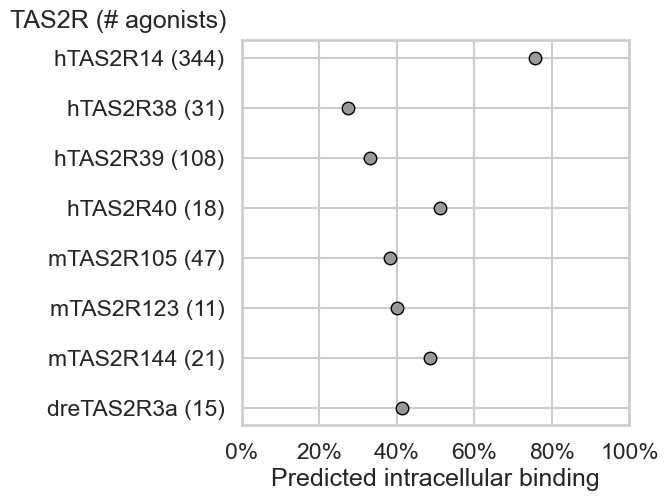

In [12]:
sns.set(rc={'figure.figsize':(5, 5)}, style='whitegrid', context='talk')
distr = binding_site_distr[(binding_site_distr['intracellular'] >= 0.2) & (binding_site_distr['ligands number'] >= 10)].reset_index(drop=True)
distr['receptor name 2'] = distr['receptor name'].astype('str') + ' (' + distr['ligands number'].astype('str') + ')'
chart = sns.scatterplot(distr, x='intracellular', y='receptor name 2', color=palette[-1], edgecolor='black', linewidth=1)
chart.set(xlabel='Predicted intracellular binding', ylabel='', xlim=(0, 1))
chart.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
chart.text(x=-0.04, y=-0.5, s='TAS2R (# agonists)', va='bottom', ha='right')
chart.figure.savefig('../figures/main/Figure 3 Predicted intracellular binding of TAS2R agonists.png', dpi=300, bbox_inches='tight')
chart

In [13]:
distr

,rID,intracellular,ligands number,receptor name,receptor name 2
0,14,0.756694,344,hTAS2R14,hTAS2R14 (344)
1,38,0.272727,31,hTAS2R38,hTAS2R38 (31)
2,39,0.329630,108,hTAS2R39,hTAS2R39 (108)
3,40,0.511111,18,hTAS2R40,hTAS2R40 (18)
4,2105,0.382979,47,mTAS2R105,mTAS2R105 (47)
5,2123,0.400000,11,mTAS2R123,mTAS2R123 (11)
6,2144,0.485714,21,mTAS2R144,mTAS2R144 (21)
7,3119,0.413333,15,dreTAS2R3a,dreTAS2R3a (15)


In [14]:
palette

[(0.8941176470588236, 0.10196078431372549, 0.10980392156862745),
 (0.21568627450980393, 0.49411764705882355, 0.7215686274509804),
 (0.30196078431372547, 0.6862745098039216, 0.2901960784313726),
 (0.596078431372549, 0.3058823529411765, 0.6392156862745098),
 (1.0, 0.4980392156862745, 0.0),
 (1.0, 1.0, 0.2),
 (0.6509803921568628, 0.33725490196078434, 0.1568627450980392),
 (0.9686274509803922, 0.5058823529411764, 0.7490196078431373),
 (0.6, 0.6, 0.6)]

In [15]:
def absolute_value(val):
    total = sum(sizes)
    absolute = int(round(val / 100 * total))
    return f'{absolute}'

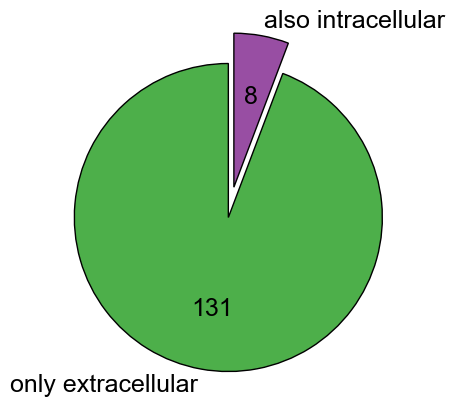

In [16]:
sizes = [131, 8]
labels = ['only extracellular', 'also intracellular']
colors = [palette[2], palette[3]]
explode = [0.0, 0.2]

sns.set(rc={'figure.figsize':(5, 5)}, style='white', context='talk')
plt.pie(sizes, labels=labels, colors=colors, radius=1, startangle=90, pctdistance=0.60, autopct=absolute_value, explode=explode, textprops={'size': 'large', 'color': 'black', 'font': 'Arial'}, wedgeprops = {'linewidth': 1, 'edgecolor':'black'})
plt.savefig('../figures/TOC pie chart.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()